<a href="https://colab.research.google.com/github/angelmalegesi0-del/COU-07506-labs/blob/main/COU07506_Week02_240242422384.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
 COU 07506 Digital Signal Processing — Week 02: Sampling, Aliasing and Quantization

 Name: ANGELA MANGIRE MALEGESI

 Registration No.: 240242422384

 Class: BEng24 COE

 Group: 4 STREAM 3

Date: 24/11/2026

In [3]:
import numpy as np
import matplotlib.pyplot as plt

In [5]:
f0 = 7.0
fs = 10.0

t = np.linspace(0, 1, 2000)

n = np.arange(0, int(fs) + 1)

tn = n / fs

f_alias = abs(f0 - fs * round(f0/fs))

print("Original frequency:", f0, "Hz")
print("Sampling frequency:", fs, "Hz")
print("Alias frequency:", f_alias, "Hz")

Original frequency: 7.0 Hz
Sampling frequency: 10.0 Hz
Alias frequency: 3.0 Hz


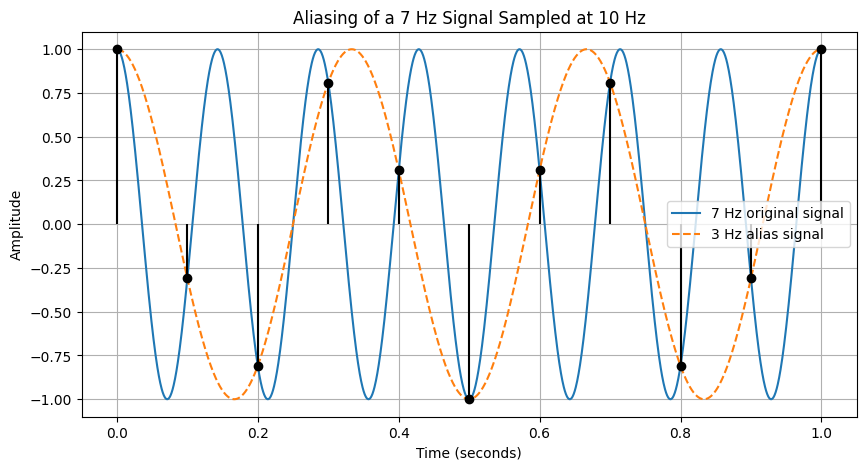

In [6]:
plt.figure(figsize=(10,5))

plt.plot(
    t,
    np.cos(2*np.pi*f0*t),
    label="7 Hz original signal"
)

plt.plot(
    t,
    np.cos(2*np.pi*f_alias*t),
    "--",
    label="3 Hz alias signal"
)

plt.stem(
    tn,
    np.cos(2*np.pi*f0*tn),
    linefmt="k-",
    markerfmt="ko",
    basefmt=" "
)

plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")
plt.title("Aliasing of a 7 Hz Signal Sampled at 10 Hz")
plt.legend()
plt.grid()
plt.show()

In [7]:
sampling_rates = [10, 12, 14, 20]

for fs in sampling_rates:

    f_alias = abs(f0 - fs * round(f0/fs))

    print("Sampling rate:", fs, "Hz",
          "| Alias frequency:", f_alias, "Hz")

Sampling rate: 10 Hz | Alias frequency: 3.0 Hz
Sampling rate: 12 Hz | Alias frequency: 5.0 Hz
Sampling rate: 14 Hz | Alias frequency: 7.0 Hz
Sampling rate: 20 Hz | Alias frequency: 7.0 Hz


In [8]:
from google.colab import files

uploaded = files.upload()

Saving Sound task 1.wav to Sound task 1.wav


In [9]:
import os
from scipy.io import wavfile
from scipy import signal
from IPython.display import Audio, display

fname = "my_voice.wav"

if os.path.exists(fname):

    fs, x = wavfile.read(fname)

    if x.ndim > 1:
        x = x.mean(axis=1)

    x = x.astype(float)

    x = x / np.max(np.abs(x))

else:

    fs = 44100

    t = np.arange(0, 3, 1/fs)

    x = 0.5 * signal.chirp(
        t, 200, 3, 15000
    )

print("Sampling rate:", fs, "Hz")
print("Number of samples:", len(x))
print("Duration:", len(x)/fs, "seconds")

Sampling rate: 44100 Hz
Number of samples: 132300
Duration: 3.0 seconds


In [10]:
for k in [2, 4, 8]:

    naive = x[::k]

    proper = signal.decimate(
        x,
        k,
        ftype="fir"
    )

    new_fs = fs // k

    print("Downsampling factor:", k)
    print("New sampling rate:", new_fs, "Hz")

    print("Naive version:")
    display(Audio(naive, rate=new_fs))

    print("Filtered version:")
    display(Audio(proper, rate=new_fs))

Downsampling factor: 2
New sampling rate: 22050 Hz
Naive version:


Filtered version:


Downsampling factor: 4
New sampling rate: 11025 Hz
Naive version:


Filtered version:


Downsampling factor: 8
New sampling rate: 5512 Hz
Naive version:


Filtered version:


In [ ]:
Naive version:the sound can have distortion
Filtered version: the sound is clear since there is no aliasing

In [11]:
def quantize(x, bits, full_scale=1.0):

    delta = 2*full_scale / 2**bits

    q = np.round(x/delta)*delta

    return np.clip(
        q,
        -full_scale,
        full_scale-delta
    )

In [12]:
fs = 8000

t = np.arange(0, 0.01, 1/fs)

x = 0.99*np.sin(2*np.pi*300*t)

xq = quantize(x, 3)

In [13]:
error = x - xq

print("Original signal samples:")
print(x[:10])

print("Quantized signal samples:")
print(xq[:10])

print("Quantization error:")
print(error[:10])

Original signal samples:
[0.         0.23111091 0.44945059 0.64295357 0.80092682 0.91464074
 0.97781146 0.98694816 0.94154595 0.84411376]
Quantized signal samples:
[0.   0.25 0.5  0.75 0.75 0.75 0.75 0.75 0.75 0.75]
Quantization error:
[ 0.         -0.01888909 -0.05054941 -0.10704643  0.05092682  0.16464074
  0.22781146  0.23694816  0.19154595  0.09411376]


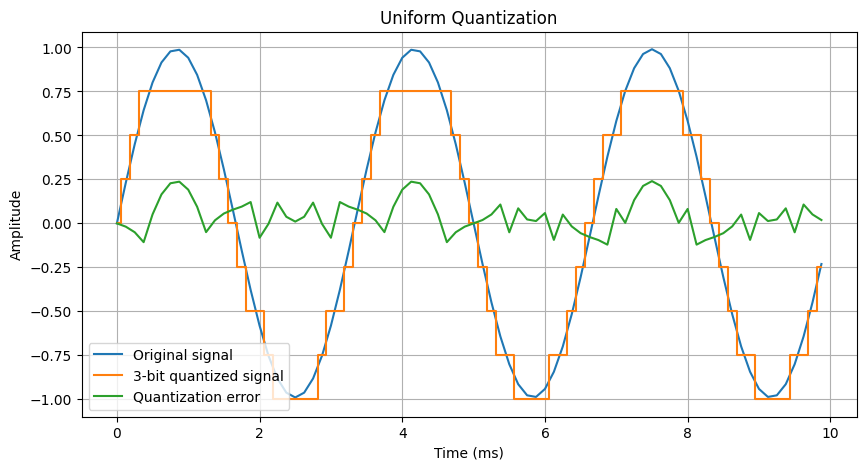

In [14]:
plt.figure(figsize=(10,5))

plt.plot(t*1e3, x, label="Original signal")

plt.step(
    t*1e3,
    xq,
    where="mid",
    label="3-bit quantized signal"
)

plt.plot(
    t*1e3,
    error,
    label="Quantization error"
)

plt.xlabel("Time (ms)")
plt.ylabel("Amplitude")
plt.title("Uniform Quantization")
plt.legend()
plt.grid()
plt.show()

In [15]:
bits = np.arange(2, 17, 2)

meas = [
    10*np.log10(
        np.sum(x**2) /
        np.sum((x - quantize(x, B))**2)
    )
    for B in bits
]

theory = 6.02*bits + 1.76

print("Bits | Measured SQNR | Theoretical SQNR")

for B, m, th in zip(bits, meas, theory):

    print(B, "|", round(m,2), "dB |", round(th,2), "dB")

Bits | Measured SQNR | Theoretical SQNR
2 | 9.6 dB | 13.8 dB
4 | 23.58 dB | 25.84 dB
6 | 36.81 dB | 37.88 dB
8 | 48.93 dB | 49.92 dB
10 | 62.81 dB | 61.96 dB
12 | 72.84 dB | 74.0 dB
14 | 88.13 dB | 86.04 dB
16 | 98.91 dB | 98.08 dB


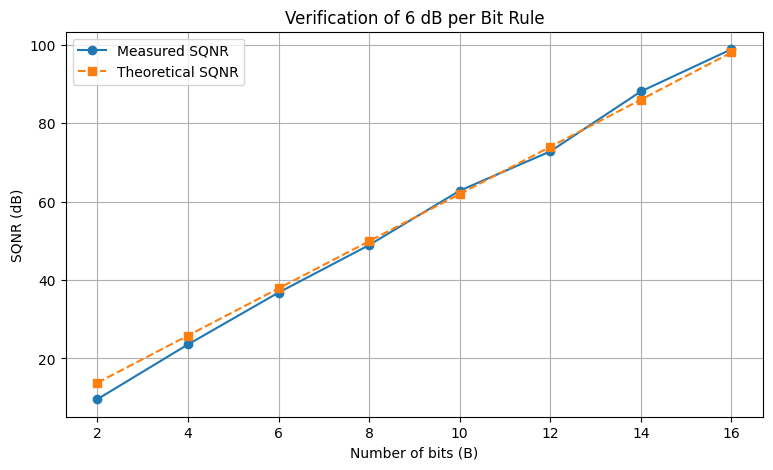

In [16]:
plt.figure(figsize=(9,5))

plt.plot(
    bits,
    meas,
    "o-",
    label="Measured SQNR"
)

plt.plot(
    bits,
    theory,
    "s--",
    label="Theoretical SQNR"
)

plt.xlabel("Number of bits (B)")
plt.ylabel("SQNR (dB)")
plt.title("Verification of 6 dB per Bit Rule")

plt.legend()
plt.grid()
plt.show()

In [20]:
fs, voice_x = wavfile.read("Sound task 1.wav")

if voice_x.ndim > 1:
    voice_x = voice_x.mean(axis=1)

voice_x = voice_x.astype(float)

voice_x = voice_x / np.max(np.abs(voice_x))

print("Sampling rate:", fs)
print("Number of samples:", len(voice_x))

Sampling rate: 48000
Number of samples: 230400


In [21]:
bits_list = [4, 8, 12]

for B in bits_list:

    voice_q = quantize(voice_x, B)

    error = voice_x - voice_q

    sqnr = 10*np.log10(
        np.sum(voice_x**2) /
        np.sum(error**2)
    )

    print("Bits:", B)
    print("SQNR:", round(sqnr, 2), "dB")

    display(
        Audio(voice_q, rate=fs)
    )

Bits: 4
SQNR: 7.17 dB


Bits: 8
SQNR: 30.62 dB


Bits: 12
SQNR: 54.69 dB


In [ ]:
AI tools used: ChatGPT.

Used for: Understanding sampling, aliasing and quantization concepts, explaining Python code, and assisting with troubleshooting.

How I verified the output: I ran the Python codes in Google Colab, checked the alias frequencies against the theoretical formula, compared measured and theoretical SQNR values, and listened to the quantized audio recordings.

In [ ]:
 Analysis Questions

Explain, with a frequency-axis sketch, why the 7 Hz tone appears at 3 Hz when .
Answer:
When a 7 Hz signal is sampled at 10 Hz, the Nyquist frequency is 5 Hz. Since 7 Hz is higher than 5 Hz, aliasing occurs. The frequency appears at 3 Hz because:
Therefore, the original 7 Hz signal appears as a 3 Hz signal after sampling.

Question 2
In Task 2.2, why can the aliasing heard in the naïve version not be removed afterwards?
Answer:
It is because the original frequency has already been mixed with other frequencies during samping

Question 3
By how much does the SNQR change when one bit is added? Does your measurement agree?
Answer:
When one bit is added the SQNR increases by approximately 6 dB,because adding one bit doubles the quantization levels and reduces quantization error.My measurement shows an increase close to 6dB per bit but may differ due to change in signal and quantization process

Question 4
A temperature changes by 0.1°C per second and the required resolution is 0.01°C over a range of 0-100°C.Suggest a sampling rate and number of bits and justify them
Answer:
To detect a change of 0.01°C the sensor should take at least 10 samples per second and 14 bits which is suitable to present 16,384 levels